In [2]:
print("hello") 

hello


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [5]:
import os, urllib.request
os.makedirs("data", exist_ok=True)
urllib.request.urlretrieve(
    "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
    "data/mnist_raw.npz")
d = np.load("data/mnist_raw.npz")
X = np.concatenate([d["x_train"], d["x_test"]]).reshape(-1, 784).astype(float)
y = np.concatenate([d["y_train"], d["y_test"]]).astype(int)
print(X.shape, y.shape)

(70000, 784) (70000,)


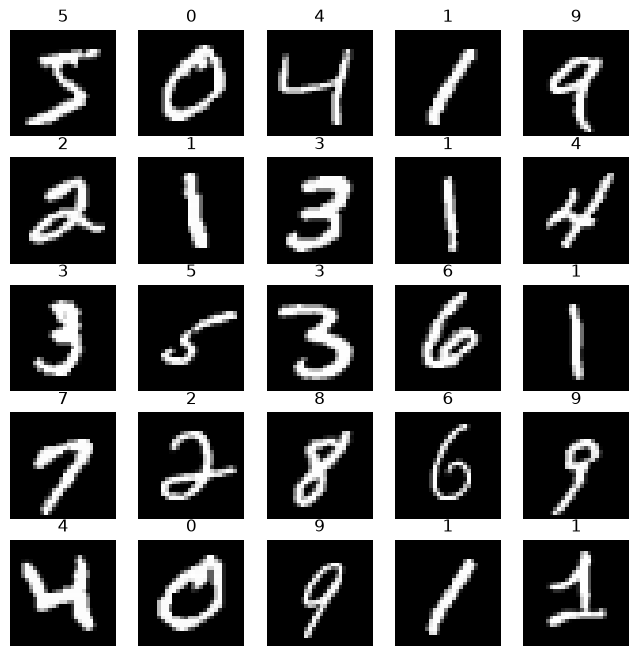

In [6]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(28, 28), cmap="gray")
    ax.set_title(y[i])
    ax.axis("off")
plt.show()


7000 is the number of images that a data having the handwritten digits 
784 is the number of pixels each image have 
y holds the labels correct answer for each label 

In [7]:
X = X / 255.0                      # pixels go from 0-255 to 0-1
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]
 
def one_hot(y, num_classes=10):
    out = np.zeros((y.shape[0], num_classes))
    out[np.arange(y.shape[0]), y] = 1
    return out
 
Y_train, Y_test = one_hot(y_train), one_hot(y_test)
print(X_train.shape, Y_train.shape)


(60000, 784) (60000, 10)


In [8]:
import os
os.makedirs("data", exist_ok=True)
np.savez_compressed("data/mnist.npz", X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)


Why divide by 255: pixels go from 0 to 255. Dividing makes them 0 to 1.
Small numbers keep training stable.

One-hot: the label 3 becomes ten numbers, all 0 except a 1 in position 3.
This matches the network's 10 outputs, one per digit.